<a href="https://colab.research.google.com/github/anupbagale/Heart_disease_prediction/blob/main/notebooks/heart_disease_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Does a heart disease model travel? Multi-centre validation on the UCI Heart Disease data

**Anup Bagale**

This notebook walks through the analysis. The heavy computation (nested,
repeated cross-validation and bootstrap confidence intervals) lives in
`scripts/run_experiments.py`, which writes the tables and figures in `results/`.
This notebook shows the method on a small live example and then reads those results.

**Question.** Models built on the Cleveland cohort are routinely reported with
AUCs around 0.9. How well do they work on patients from *other hospitals*,
and what goes wrong when they don't?

Contents
1. Data: four hospitals
2. What was wrong with version 1 of this project
3. Method: a leakage-free pipeline (live example)
4. Internal validation on Cleveland
5. External validation at three other hospitals
6. Calibration and clinical usefulness
7. What drives the predictions
8. Performance by sex
9. Conclusions and limitations

**Running on Google Colab:** run the next cell first. It downloads the repository and
installs it (about 1 minute). Locally, run `pip install -e .` from the repository root instead.

In [1]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/Heart_disease_prediction"
    if not os.path.exists(REPO):
        !git clone -q https://github.com/anupbagale/Heart_disease_prediction {REPO}
        %pip install -q -e {REPO}
    # Make the package importable straight away (no runtime restart needed).
    if f"{REPO}/src" not in sys.path:
        sys.path.insert(0, f"{REPO}/src")
    os.chdir(f"{REPO}/notebooks")

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from IPython.display import Image, display

from heartdisease.data import (FEATURES, FEATURES_REDUCED, SITES, TARGET,
                               cohort_table, load_all, load_site)
from heartdisease.models import MODEL_NAMES, make_model
from heartdisease.evaluation import repeated_cv_predictions, summarise_with_ci

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
FIG, TAB = RESULTS / "figures", RESULTS / "tables"
pd.set_option("display.precision", 3)
show = lambda name, width=None: display(Image(filename=str(FIG / name), width=width))

## 1. Data: four hospitals

The UCI Heart Disease dataset is usually used as "the Cleveland data", but it
contains patients referred for coronary angiography at **four** centres.
The outcome is angiographic coronary artery disease (> 50 % narrowing of any
major vessel). The cohorts differ a lot, most strikingly in how many patients
have disease.

In [3]:
df = load_all()
cohort_table(df)

,Cleveland,Hungary,Switzerland,VA Long Beach
n,303,294,123,200
disease prevalence (%),45.9,36.1,93.5,74.5
"age, mean (SD)",54.4 (9.0),47.8 (7.8),55.3 (9.0),59.4 (7.8)
male (%),68.0,72.4,91.9,97.0
asymptomatic chest pain (%),47.5,41.8,79.7,65.5
exercise angina (%),32.7,30.4,44.3,64.6


Missing data are also very different. Three exercise and imaging tests (`slope`, `ca`, `thal`)
were rarely recorded outside Cleveland, and Switzerland recorded no cholesterol at all
(the raw file codes it as 0 mg/dl, which `load_site` converts to missing).

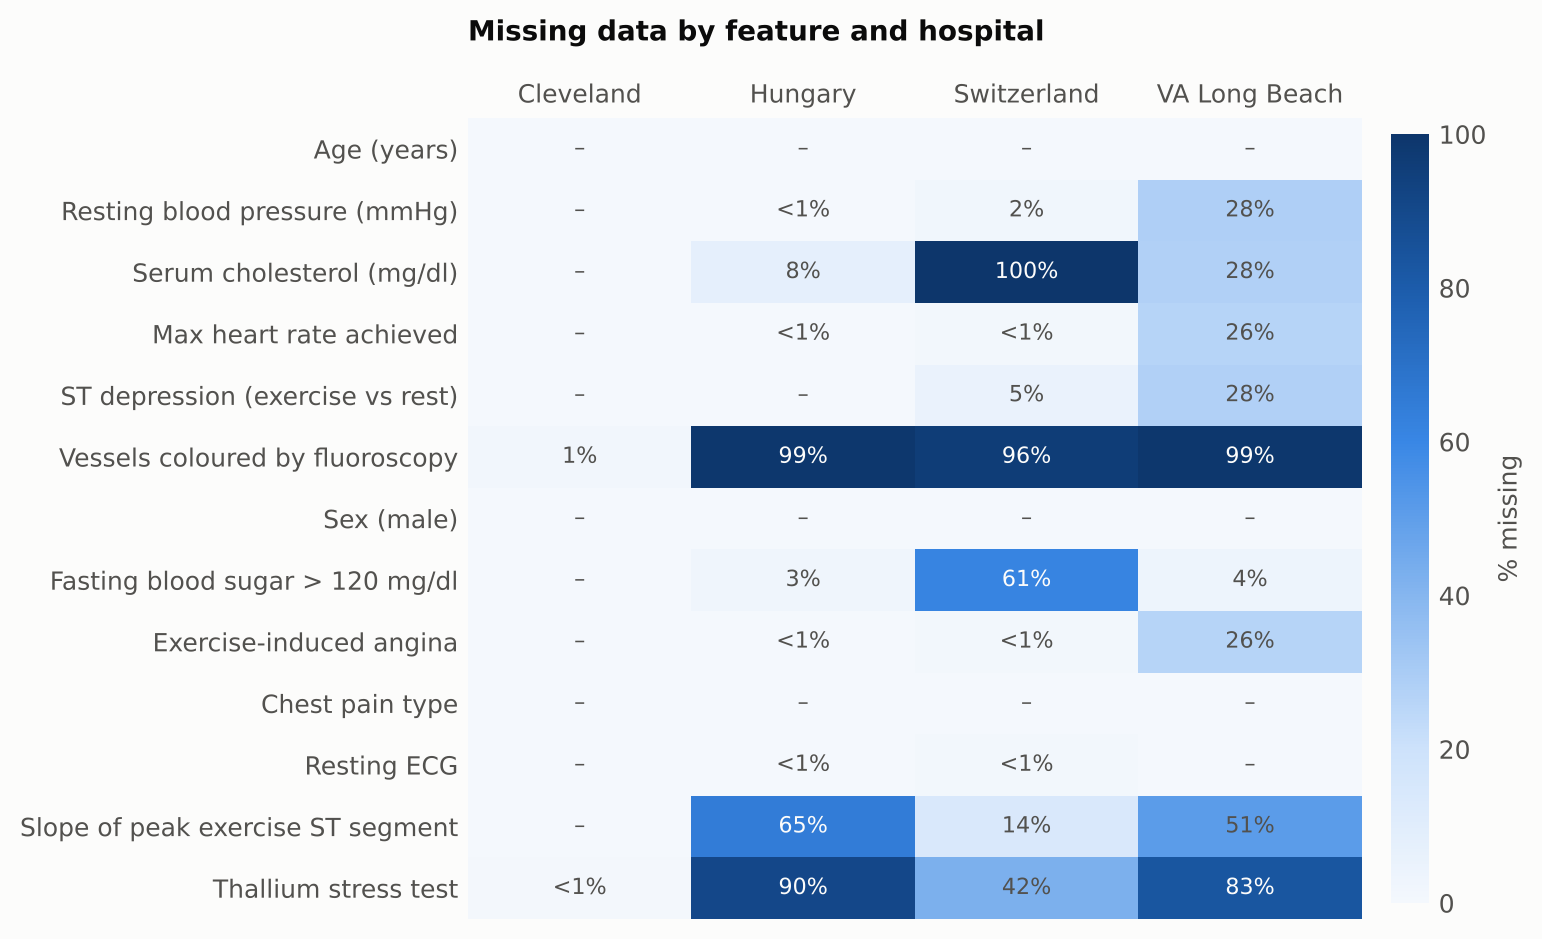

In [4]:
show("missingness.png", 560)

## 2. What was wrong with version 1 of this project

The first version of this repository trained a Keras network with a sigmoid
output and binary cross-entropy directly on the column `num`. But `num` takes
values **0-4**:

In [5]:
cle = load_site("cleveland")
print(cle["num"].value_counts().sort_index().to_string())
print(f"\nShare without disease (num = 0): {(cle.num == 0).mean():.1%}")

num
0    164
1     55
2     36
3     35
4     13

Share without disease (num = 0): 54.1%


Binary cross-entropy assumes labels in {0, 1}. With labels of 2, 3 or 4 the
loss can become negative and unbounded, which is why the training log showed a
test loss of about -1887. The model learned nothing useful: its test accuracy
of 55.7 % is roughly what you get by predicting "no disease" for everyone
(54.1 % above).

Three further problems:

* **Leakage.** The mean imputer was fitted on all 303 patients before the
  train/test split, so test-set information leaked into training.
* **Encoding.** Categorical variables (chest-pain type, ECG, ST slope,
  thallium result) were treated as numbers, and the vessel count `ca` was mean-imputed
  to fractional values.
* **Evaluation.** One 80/20 split of 303 patients (61 test patients) gives a very noisy estimate,
  and accuracy alone says nothing about calibration or clinical value.

The fix for the outcome is the convention of the original studies:

In [6]:
y = (cle["num"] > 0).astype(int)   # what load_site() stores as `target`
assert (y == cle[TARGET]).all()
y.value_counts()

num
0    164
1    139
Name: count, dtype: int64

## 3. Method: a leakage-free pipeline (live example)

Every preprocessing step sits inside an sklearn `Pipeline`:
median imputation and scaling for numeric features, most-frequent imputation
for binary features, and most-frequent imputation plus one-hot encoding for
categorical ones. The pipeline is wrapped in a small inner grid search. When this
object is cross-validated, imputation, scaling *and* hyperparameter choice
all happen inside each training fold (**nested cross-validation**).

In [7]:
model = make_model("logreg", FEATURES)
model

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

A live run with logistic regression: 5-fold CV repeated 3 times, with a
bootstrap 95 % CI. The full analysis uses 10 repeats, 2,000 bootstrap samples and four models.

In [8]:
P, chosen = repeated_cv_predictions("logreg", cle, cle[TARGET].to_numpy(), FEATURES,
                                    n_repeats=3, n_jobs=1)
summarise_with_ci(cle[TARGET].to_numpy(), P, n_boot=300).loc[
    ["AUC", "Sensitivity", "Specificity", "Brier", "Calibration slope"]]

,estimate,ci_low,ci_high
AUC,0.911,0.880,0.938
Sensitivity,0.791,0.729,0.851
Specificity,0.904,0.863,0.941
Brier,0.117,0.099,0.137
Calibration slope,1.185,0.981,1.512


## 4. Internal validation on Cleveland

Four model families, from simplest to most flexible: penalised logistic
regression, random forest, XGBoost, and a small neural network (MLP).

In [9]:
internal = pd.read_csv(TAB / "internal_validation_long.csv")
fmt = lambda r: f"{r.estimate:.3f} ({r.ci_low:.3f}-{r.ci_high:.3f})"
internal["value"] = internal.apply(fmt, axis=1)
keep = ["AUC", "Sensitivity", "Specificity", "Brier", "Calibration slope"]
(internal[(internal.feature_set == "All 13 features") & internal.metric.isin(keep)]
 .pivot(index="model_name", columns="metric", values="value")[keep])

metric,AUC,Sensitivity,Specificity,Brier,Calibration slope
model_name,,,,,
Logistic regression,0.908 (0.875-0.939),0.785 (0.717-0.846),0.901 (0.859-0.939),0.119 (0.099-0.141),1.160 (0.936-1.509)
Neural network (MLP),0.910 (0.877-0.941),0.796 (0.726-0.858),0.901 (0.859-0.938),0.117 (0.095-0.139),1.112 (0.908-1.426)
Random forest,0.906 (0.872-0.937),0.781 (0.713-0.843),0.884 (0.838-0.924),0.129 (0.111-0.146),1.677 (1.383-2.159)
XGBoost,0.902 (0.868-0.934),0.796 (0.730-0.854),0.873 (0.826-0.916),0.124 (0.101-0.149),0.854 (0.713-1.065)


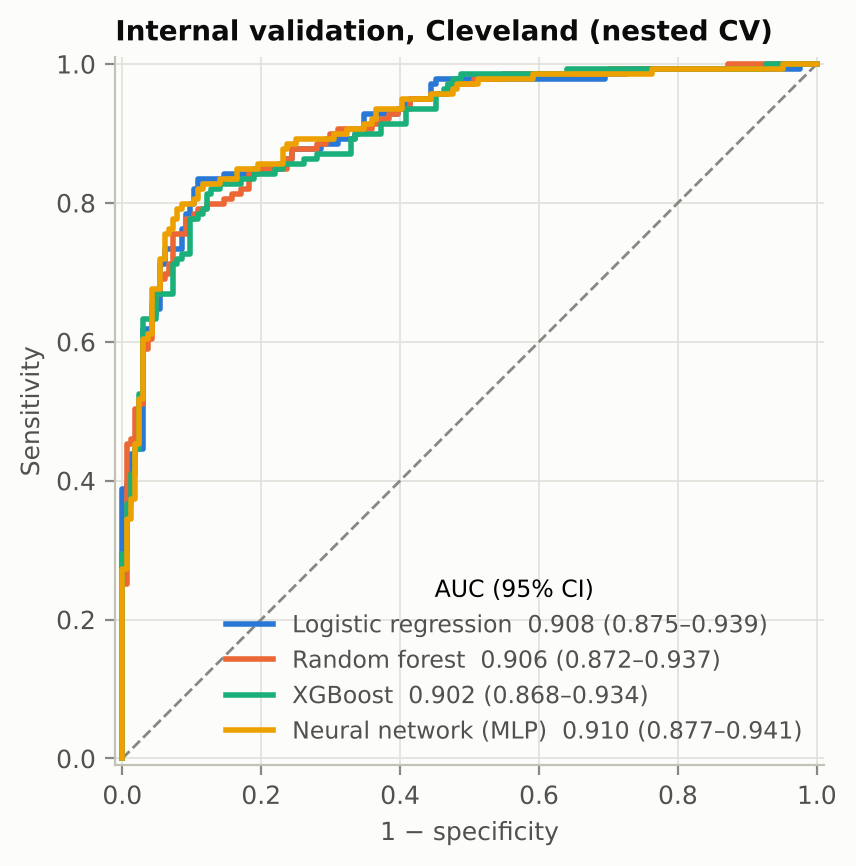

In [10]:
show("roc_internal.png", 460)

Is any flexible model better than logistic regression? The paired bootstrap
difference in AUC answers this directly:

In [11]:
pd.read_csv(TAB / "internal_auc_differences.csv").round(3)

,feature_set,model,comparison,difference,ci_low,ci_high
0,All 13 features,Random forest,minus logistic regression,-0.001,-0.012,0.010
1,All 13 features,XGBoost,minus logistic regression,-0.006,-0.020,0.009
2,All 13 features,Neural network (MLP),minus logistic regression,0.002,-0.001,0.005
3,"10 features (no slope, ca, thal)",Random forest,minus logistic regression,-0.007,-0.022,0.006
4,"10 features (no slope, ca, thal)",XGBoost,minus logistic regression,-0.011,-0.027,0.004
5,"10 features (no slope, ca, thal)",Neural network (MLP),minus logistic regression,0.002,-0.004,0.008


## 5. External validation at three other hospitals

Each model is tuned and trained on all Cleveland patients, then applied
**unchanged** to Hungary, Switzerland and VA Long Beach. This is repeated with
a 10-feature set that drops the three mostly-missing tests. The right-hand
panel is leave-one-site-out: train on three hospitals, test on the fourth.

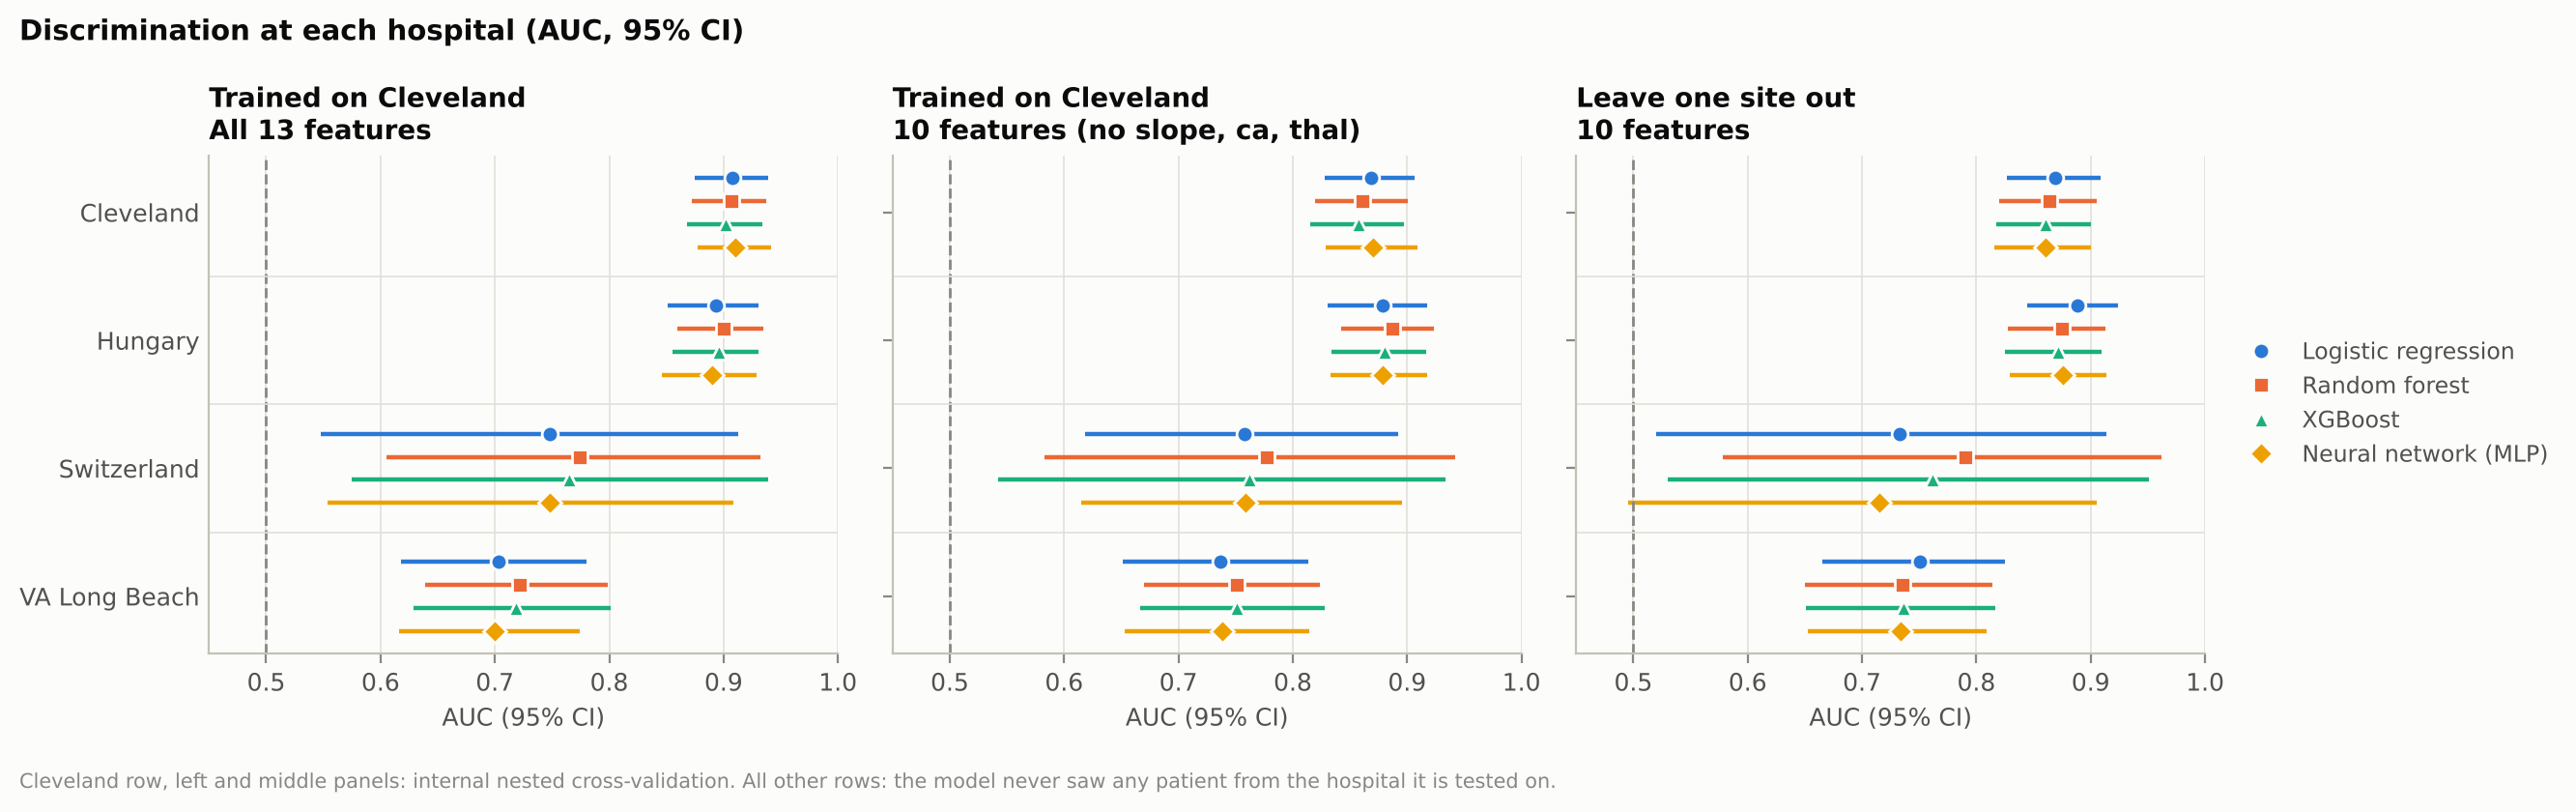

In [12]:
show("external_validation_auc.png")

In [13]:
ext = pd.read_csv(TAB / "external_validation_long.csv")
ext["value"] = ext.apply(fmt, axis=1)
(ext[(ext.validation == "Cleveland -> site") & (ext.metric == "AUC")]
 .pivot_table(index=["feature_set", "test_site_name"], columns="model_name",
              values="value", aggfunc="first"))

model_name                                       Logistic regression  \
feature_set                      test_site_name                        
10 features (no slope, ca, thal) Hungary         0.878 (0.830-0.917)   
                                 Switzerland     0.758 (0.618-0.892)   
                                 VA Long Beach   0.737 (0.651-0.813)   
All 13 features                  Hungary         0.894 (0.851-0.930)   
                                 Switzerland     0.748 (0.548-0.913)   
                                 VA Long Beach   0.703 (0.618-0.780)   

model_name                                      Neural network (MLP)  \
feature_set                      test_site_name                        
10 features (no slope, ca, thal) Hungary         0.879 (0.833-0.917)   
                                 Switzerland     0.759 (0.615-0.896)   
                                 VA Long Beach   0.738 (0.653-0.814)   
All 13 features                  Hungary         0.890 (0.846-0.929)   
                                 Switzerland     0.748 (0.553-0.909)   
                                 VA Long Beach   0.699 (0.616-0.774)   

model_name                                             Random forest  \
feature_set                      test_site_name                        
10 features (no slope, ca, thal) Hungary         0.887 (0.842-0.924)   
                                 Switzerland     0.777 (0.583-0.942)   
                                 VA Long Beach   0.751 (0.670-0.824)   
All 13 features                  Hungary         0.900 (0.859-0.935)   
                                 Switzerland     0.774 (0.605-0.933)   
                                 VA Long Beach   0.722 (0.639-0.799)   

model_name                                                   XGBoost  
feature_set                      test_site_name                       
10 features (no slope, ca, thal) Hungary         0.880 (0.833-0.917)  
                                 Switzerland     0.762 (0.542-0.934)  
                                 VA Long Beach   0.751 (0.667-0.828)  
All 13 features                  Hungary         0.896 (0.855-0.930)  
                                 Switzerland     0.765 (0.575-0.939)  
                                 VA Long Beach   0.719 (0.629-0.801)

## 6. Calibration and clinical usefulness

Discrimination (AUC) only asks whether patients with disease are ranked above
patients without it. A clinician also needs the predicted *probability* to be
right. Calibration-in-the-large (intercept) should be 0 and the calibration slope 1.

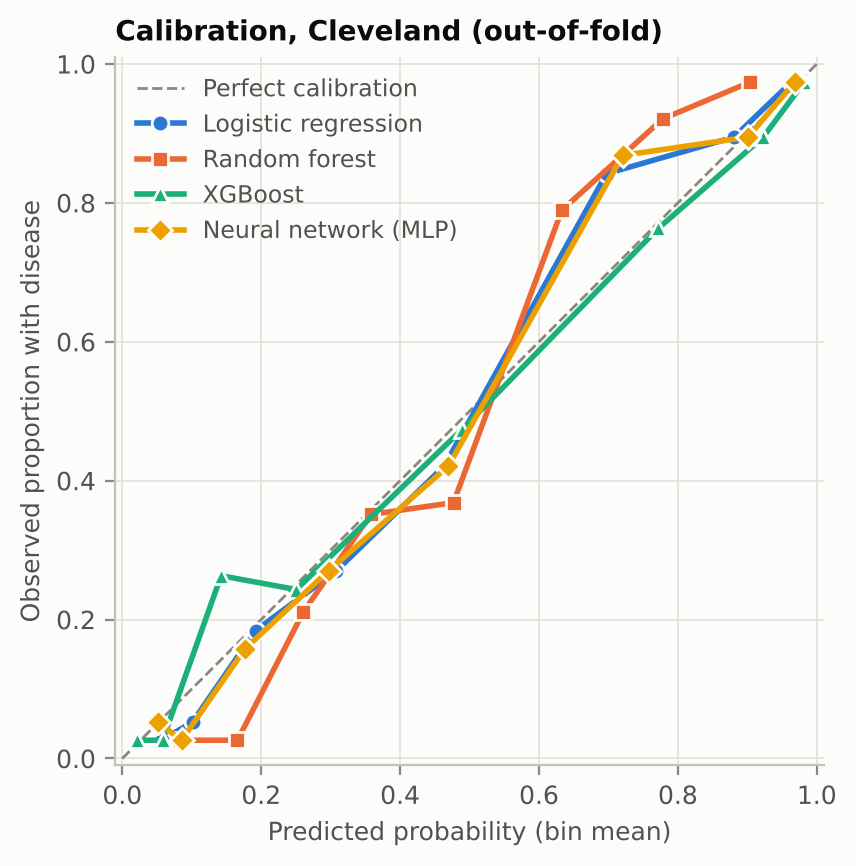

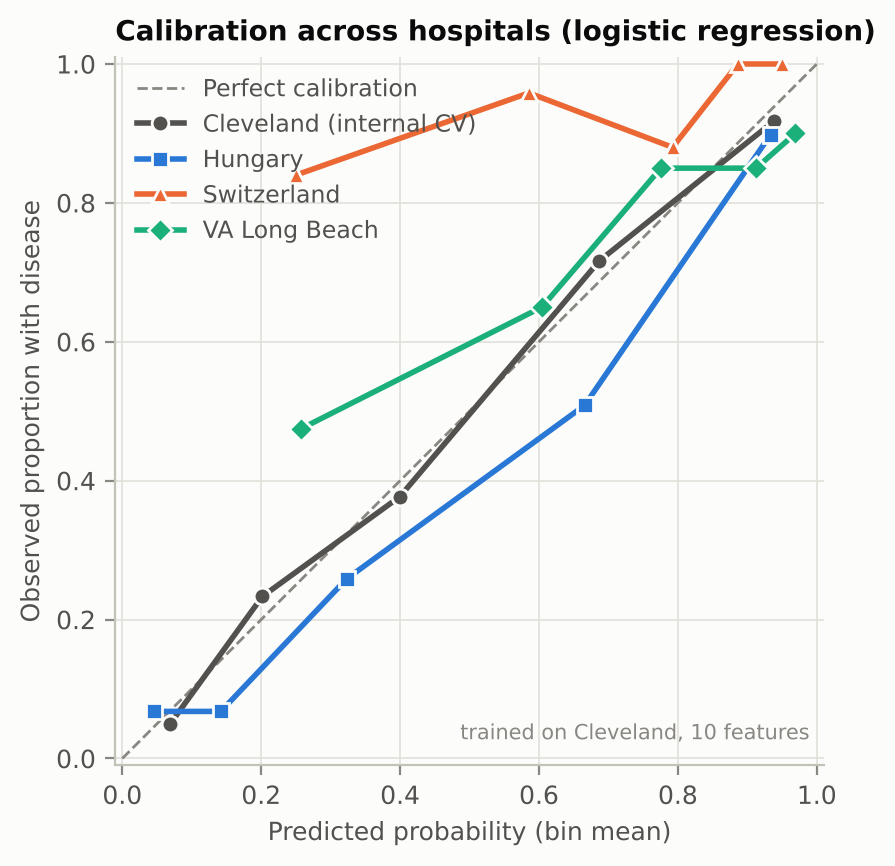

In [14]:
show("calibration_internal.png", 430)
show("calibration_external.png", 430)

In [15]:
(ext[(ext.validation == "Cleveland -> site") & (ext.model == "logreg")
     & ext.metric.isin(["Calibration intercept", "Calibration slope",
                        "Mean predicted risk", "Observed prevalence"])]
 .pivot_table(index=["feature_set", "test_site_name"], columns="metric",
              values="estimate", aggfunc="first").round(2))

metric                                           Calibration intercept  \
feature_set                      test_site_name                          
10 features (no slope, ca, thal) Hungary                         -0.49   
                                 Switzerland                      2.60   
                                 VA Long Beach                    0.30   
All 13 features                  Hungary                          0.45   
                                 Switzerland                      3.21   
                                 VA Long Beach                    1.78   

metric                                           Calibration slope  \
feature_set                      test_site_name                      
10 features (no slope, ca, thal) Hungary                      0.91   
                                 Switzerland                  0.59   
                                 VA Long Beach                0.57   
All 13 features                  Hungary                      1.55   
                                 Switzerland                  0.90   
                                 VA Long Beach                0.69   

metric                                           Mean predicted risk  \
feature_set                      test_site_name                        
10 features (no slope, ca, thal) Hungary                        0.42   
                                 Switzerland                    0.69   
                                 VA Long Beach                  0.70   
All 13 features                  Hungary                        0.29   
                                 Switzerland                    0.51   
                                 VA Long Beach                  0.42   

metric                                           Observed prevalence  
feature_set                      test_site_name                       
10 features (no slope, ca, thal) Hungary                        0.36  
                                 Switzerland                    0.93  
                                 VA Long Beach                  0.74  
All 13 features                  Hungary                        0.36  
                                 Switzerland                    0.93  
                                 VA Long Beach                  0.74

Decision curve analysis asks whether using the model to decide who is referred
for angiography beats referring everyone or no one, across the range of
risk thresholds a clinician might choose.

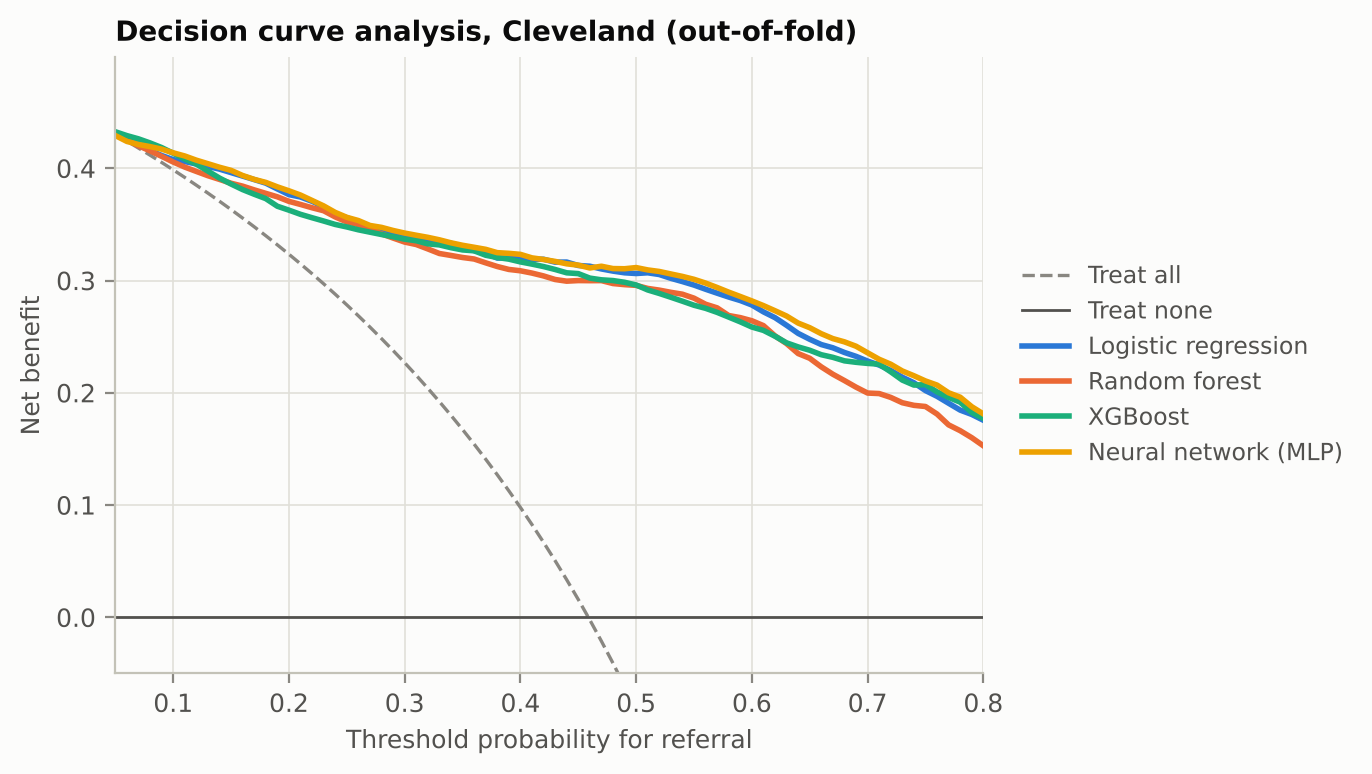

In [16]:
show("decision_curve.png", 560)

## 7. What drives the predictions

Two complementary views: odds ratios from the penalised logistic regression
(numeric features per standard deviation; categories against the
reference level: typical angina, normal ECG, upsloping ST, normal thallium), and SHAP
values from XGBoost.

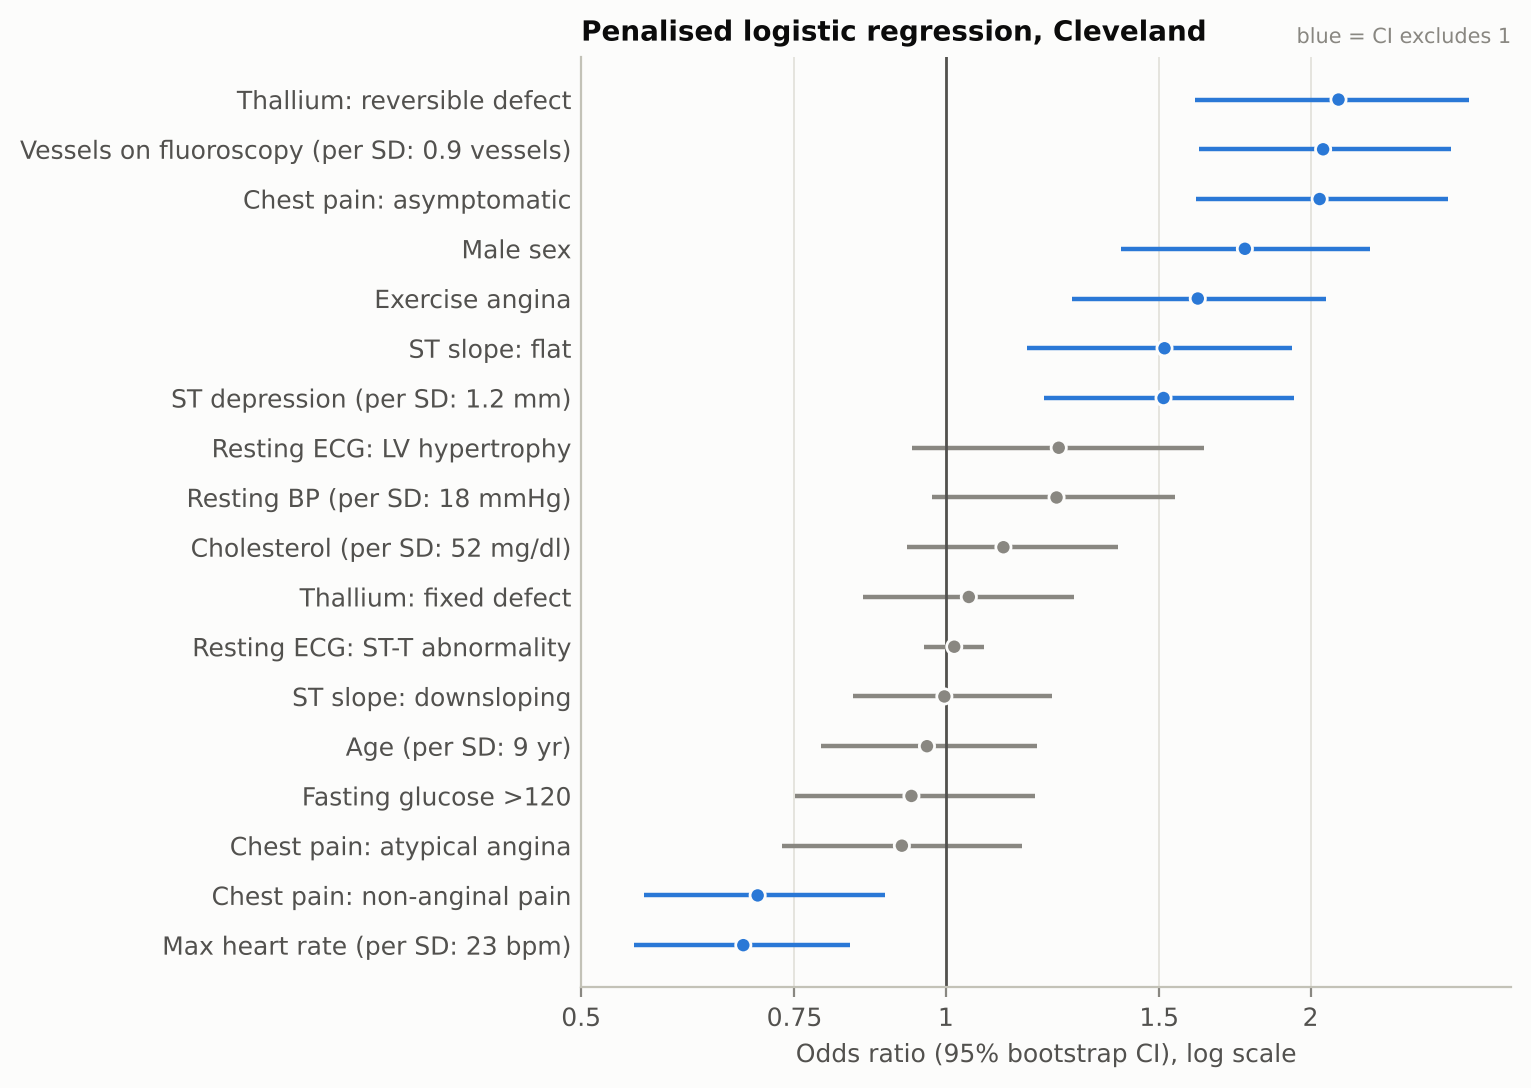

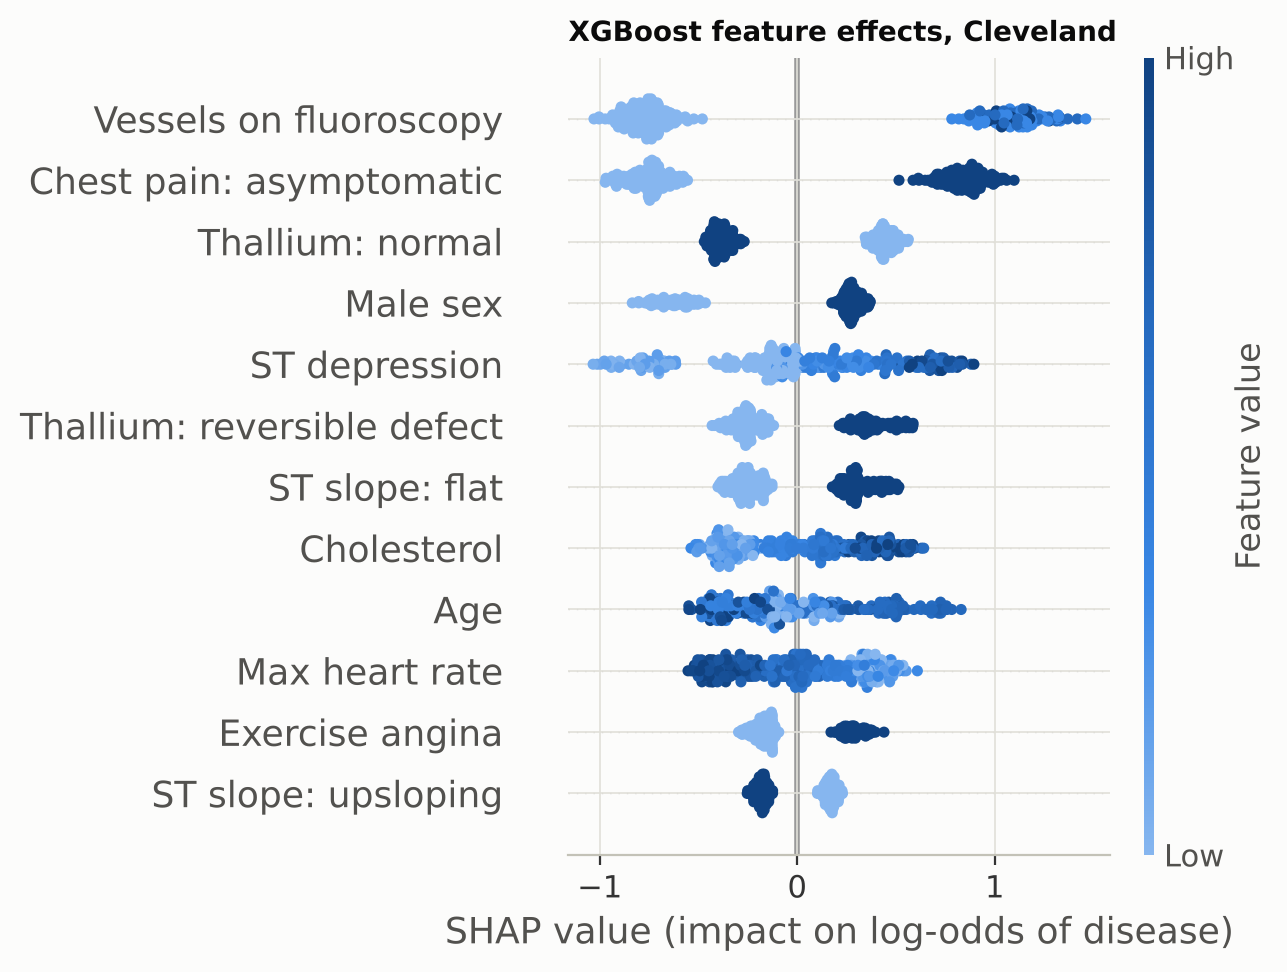

In [17]:
show("odds_ratios.png", 560)
show("shap_xgboost.png", 560)

## 8. Performance by sex

Women make up about a third of the Cleveland cohort and have a much lower
prevalence of disease, so the same model can behave differently for them.

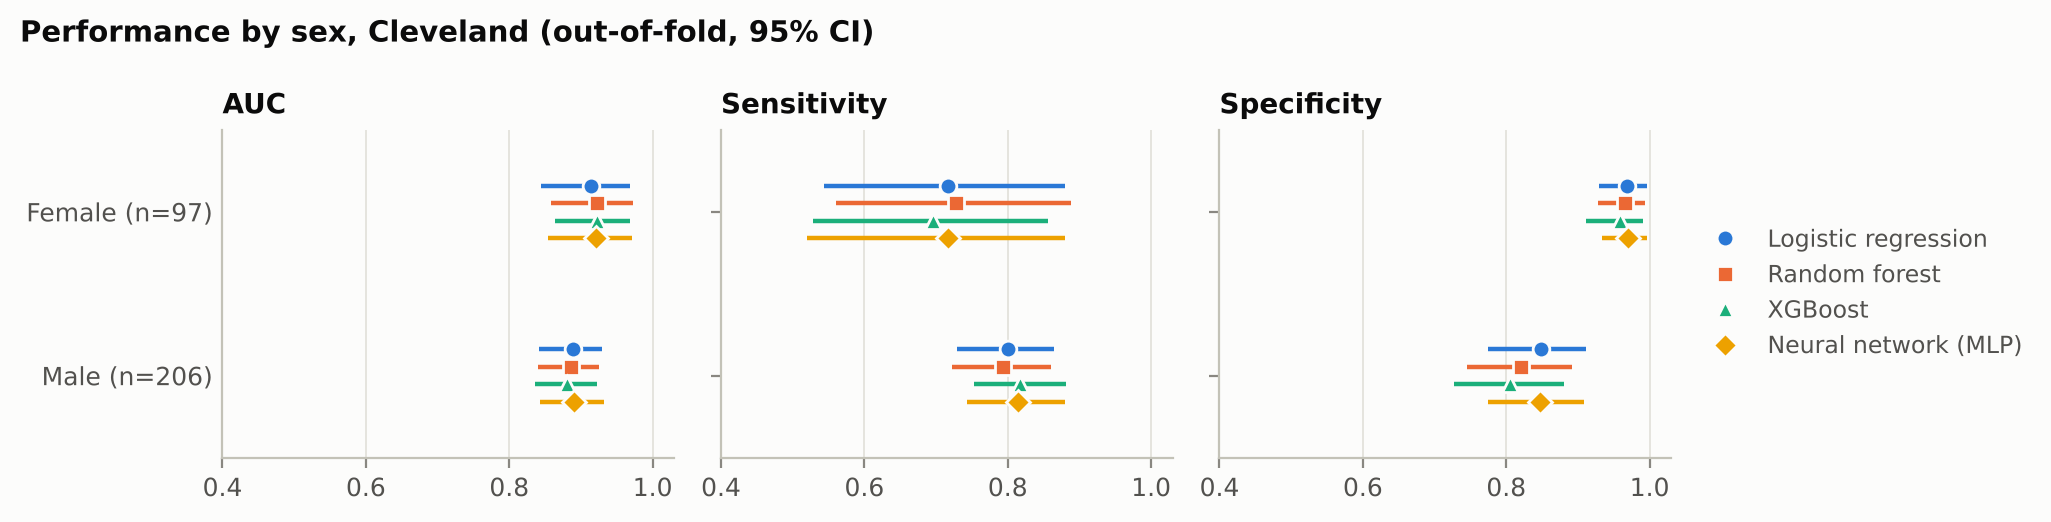

metric,AUC,Observed prevalence,Sensitivity,Specificity
group,,,,
Female (n=97),0.915 (0.844-0.969),0.258 (0.258-0.258),0.716 (0.544-0.880),0.968 (0.929-0.996)
Male (n=206),0.889 (0.842-0.930),0.553 (0.553-0.553),0.800 (0.729-0.865),0.848 (0.775-0.911)


In [18]:
show("subgroup_sex.png")
sub = pd.read_csv(TAB / "subgroup_sex.csv")
sub["value"] = sub.apply(fmt, axis=1)
sub[sub.model == "logreg"].pivot(index="group", columns="metric", values="value")

## 9. Conclusions and limitations

See the README and `docs/report.md` for the full discussion. In brief:

* With the outcome fixed and a leakage-free pipeline, every model reaches high
  discrimination on Cleveland, and the flexible models do **not** beat logistic regression.
* Performance falls at other hospitals, sharply so at Switzerland and VA.
  Calibration fails most, mainly because disease prevalence differs between centres.
  Any deployment would need local recalibration.
* Filling structurally missing tests with values learned at another hospital
  hurts. A smaller model built only on routinely available features transfers better.

**Limitations.** Small cohorts (Switzerland has only 8 patients without disease, so
specificity there is very uncertain); data collected in the 1980s; bootstrap CIs
reflect test-set sampling but not model-refitting variability; the outcome
definition is fixed by the dataset.

## 10. Re-run the analysis yourself

Everything above reads results computed by `scripts/run_experiments.py`. To check
them, set `RUN_ANALYSIS = True` and run the cell below. The quick mode
(2 cross-validation repeats, 200 bootstrap samples) takes about 7 minutes on Colab
and writes to `results_quick/`. The full mode (10 repeats, 2,000 bootstrap samples,
about 20 minutes) reproduces `results/` exactly.

In [19]:
RUN_ANALYSIS = False   # set to True to recompute every table and figure
QUICK = True           # False = full run, identical to the committed results

if RUN_ANALYSIS:
    !cd "{ROOT}" && python -m pytest -q
    !cd "{ROOT}" && python scripts/run_experiments.py {"--quick" if QUICK else ""}
    out = ROOT / ("results_quick" if QUICK else "results")
    new = pd.read_csv(out / "tables" / "internal_validation_long.csv")
    display(new[(new.feature_set == "All 13 features") & (new.metric == "AUC")]
            [["model_name", "estimate", "ci_low", "ci_high"]])
else:
    print("Skipped. Set RUN_ANALYSIS = True and run this cell to recompute everything.")

Skipped. Set RUN_ANALYSIS = True and run this cell to recompute everything.
